In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

data_dir = "/Users/shouryakulkarni/IDX-Exchange-Data-Science"
target = "ClosePrice"
pd.set_option('display.max_columns', 50)

In [2]:
clean = pd.read_csv(f"{data_dir}/data/cleaned_sfr_districts.csv",
                    dtype={"PostalCode": str, "ElemDistrict": str, "HighDistrict": str},
                    parse_dates=["CloseDate"])

saved = joblib.load(f"{data_dir}/best_model.joblib")
model, bounds, features = saved["model"], saved["bounds"], saved["features"]
print("Trained on:", saved["train_months"][0], "to", saved["train_months"][-1])
print("Test month:", saved["test_month"])

Trained on: 2025-09 to 2026-03
Test month: 2026-04


In [3]:
def apply_outlier_bounds(data, b):
    ppsf = data[target] / data["LivingArea"]
    keep = (data[target].between(b["price_lo"], b["price_hi"]) &
            ppsf.between(b["ppsf_lo"], b["ppsf_hi"]))
    return data[keep]

test = clean[clean["CloseMonth"] == saved["test_month"]]
test_f = apply_outlier_bounds(test, bounds)

res = test_f[[target, "CountyOrParish", "City", "LivingArea"]].copy()
res["predicted"] = np.exp(model.predict(test_f[features]))
res["pct_err"] = (res["predicted"] - res[target]) / res[target]      # + = too high, − = too low
print(f"{len(test):,} April sales -> {len(test_f):,} after outlier cutoffs")

12,455 April sales -> 12,262 after outlier cutoffs


In [4]:
y, p = res[target].values, res["predicted"].values
abs_pct = np.abs(res["pct_err"])

overall = pd.Series({
    "Homes": len(res),
    "R²": r2_score(y, p),
    "MAE $": mean_absolute_error(y, p),
    "RMSE $": np.sqrt(mean_squared_error(y, p)),
    "MAPE %": abs_pct.mean() * 100,
    "MdAPE %": abs_pct.median() * 100,
    "Within 10 %": (abs_pct <= 0.10).mean() * 100,
    "Within 20 %": (abs_pct <= 0.20).mean() * 100,
    "Bias %": res["pct_err"].median() * 100,
})
overall.round(3)

Homes           12262.000
R²                  0.892
MAE $          155926.164
RMSE $         320996.277
MAPE %             11.194
MdAPE %             7.706
Within 10 %        60.104
Within 20 %        85.296
Bias %             -2.267
dtype: float64

In [6]:
def segment_metrics(df):
    pct = df["pct_err"]
    return pd.Series({
        "Homes": len(df),
        "Min price": df[target].min(),
        "Max price": df[target].max(),
        "MdAPE %": pct.abs().median() * 100,
        "MAPE %": pct.abs().mean() * 100,
        "MAE $": (df["predicted"] - df[target]).abs().mean(),
        "Bias %": pct.median() * 100,
        "Within 20 %": (pct.abs() <= 0.20).mean() * 100,
    })

In [7]:
res["price_band"] = pd.qcut(res[target], 5,
                            labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
by_band = res.groupby("price_band", observed=True).apply(segment_metrics)
by_band.round(1)

,Homes,Min price,Max price,MdAPE %,MAPE %,MAE $,Bias %,Within 20 %
price_band,,,,,,,,
Q1 cheapest,2487.0,185000.0,575000.0,6.9,11.9,48832.3,0.8,85.4
Q2,2475.0,575003.0,800000.0,6.0,8.6,58999.9,-1.0,91.2
Q3,2400.0,801663.0,1099000.0,6.8,9.2,85028.6,-2.2,91.2
Q4,2449.0,1099900.0,1655000.0,8.5,11.5,154494.9,-3.8,85.1
Q5 priciest,2451.0,1657900.0,8900000.0,11.9,14.8,433320.8,-7.9,73.6


In [10]:
by_county = res.groupby("CountyOrParish").apply(segment_metrics)
by_county = by_county[by_county["Homes"] >= 200].sort_values("MdAPE %")
by_county.round(1)

,Homes,Min price,Max price,MdAPE %,MAPE %,MAE $,Bias %,Within 20 %
CountyOrParish,,,,,,,,
Riverside,1877.0,185000.0,7675000.0,6.3,9.8,95633.5,-1.5,88.4
San Bernardino,1228.0,185000.0,4000000.0,6.6,9.5,57840.1,-1.4,89.5
Orange,1168.0,400000.0,8900000.0,7.3,9.7,196205.3,-2.8,89.8
Ventura,418.0,300000.0,7400000.0,8.0,11.4,174953.3,-2.8,84.0
Contra Costa,583.0,250000.0,8300000.0,8.1,10.7,136800.9,-2.6,85.9
San Luis Obispo,215.0,355000.0,7900000.0,8.1,12.3,162104.4,-0.8,82.3
Los Angeles,3013.0,200000.0,8900000.0,8.2,11.6,184212.0,-2.3,83.9
San Diego,1435.0,232000.0,7850000.0,8.3,11.5,179292.2,-2.5,86.2
Santa Clara,392.0,296820.0,7000000.0,9.1,12.3,277333.7,-3.3,84.2


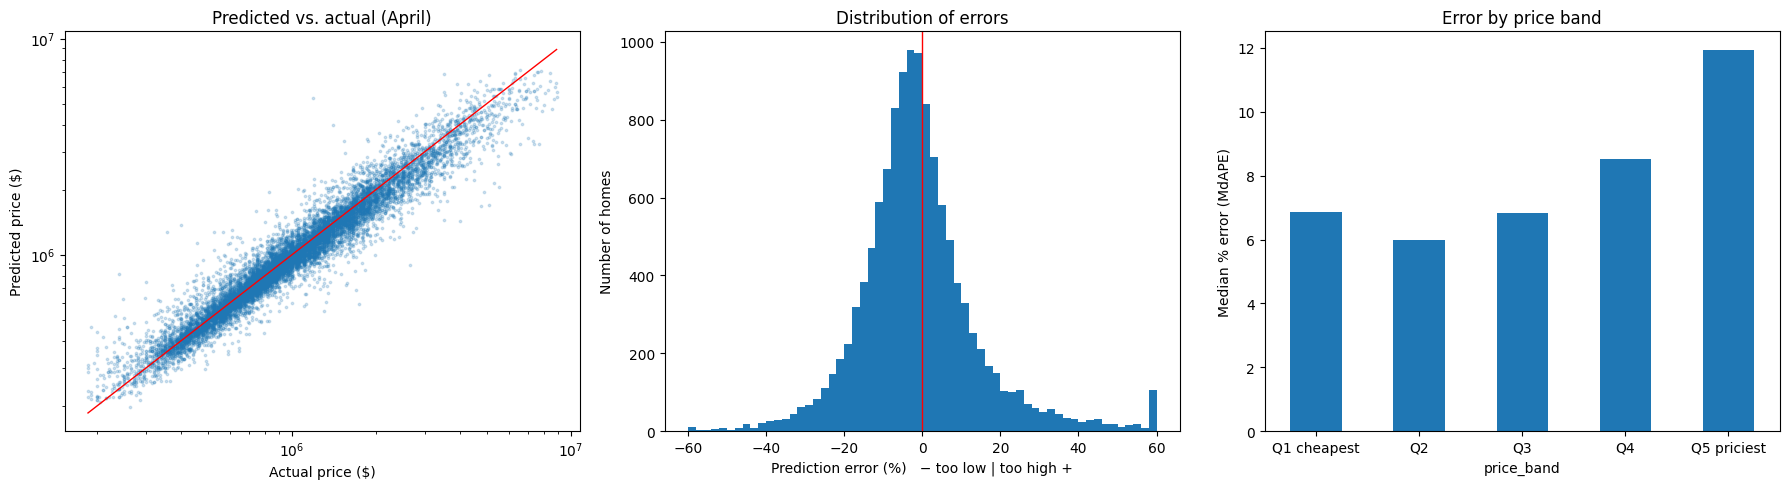

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Predicted vs. actual
axes[0].scatter(res[target], res["predicted"], s=3, alpha=0.2)
lims = [res[target].min(), res[target].max()]
axes[0].plot(lims, lims, color="red", linewidth=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Predicted vs. actual (April)")

# 2. Error distribution
axes[1].hist(res["pct_err"].clip(-0.6, 0.6) * 100, bins=60)
axes[1].axvline(0, color="red", linewidth=1)
axes[1].set_xlabel("Prediction error (%)   − too low | too high +")
axes[1].set_ylabel("Number of homes")
axes[1].set_title("Distribution of errors")

# 3. MdAPE by price band
by_band["MdAPE %"].plot.bar(ax=axes[2])
axes[2].set_ylabel("Median % error (MdAPE)")
axes[2].set_title("Error by price band")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [9]:
res.assign(pct_err=res["pct_err"] * 100).sort_values("pct_err", key=abs, ascending=False) \
   .head(10).round(1)

,ClosePrice,CountyOrParish,City,LivingArea,predicted,pct_err,price_band
107178,1184000.0,San Diego,La Jolla,3116.0,5.312646e+06,348.7,Q4
99744,355000.0,Santa Clara,Los Gatos,1248.0,1.266214e+06,256.7,Q1 cheapest
105314,400000.0,Los Angeles,Sun Valley,2537.0,1.367810e+06,242.0,Q1 cheapest
102275,240000.0,San Diego,San Marcos,1680.0,8.096210e+05,237.3,Q1 cheapest
106393,1400000.0,Los Angeles,Los Angeles,4790.0,3.994652e+06,185.3,Q4
95959,247878.0,Los Angeles,Compton,996.0,6.204572e+05,150.3,Q1 cheapest
102510,300000.0,Ventura,Camarillo,1689.0,7.496000e+05,149.9,Q1 cheapest
103794,455000.0,Santa Cruz,Aptos,1548.0,1.129332e+06,148.2,Q1 cheapest
104344,190000.0,San Joaquin,Stockton,1294.0,4.615414e+05,142.9,Q1 cheapest
95075,525000.0,Los Angeles,Westlake Village,1776.0,1.266513e+06,141.2,Q1 cheapest


In [12]:
overall_row = pd.DataFrame([{"segment_type": "overall", "segment": "All April homes",
                             **segment_metrics(res)}])
band_rows = by_band.reset_index().rename(columns={"price_band": "segment"}).assign(segment_type="price band")
county_rows = by_county.reset_index().rename(columns={"CountyOrParish": "segment"}).assign(segment_type="county")

metrics_summary = pd.concat([overall_row, band_rows, county_rows], ignore_index=True)
metrics_summary.insert(0, "model", "XGBoost")
metrics_summary.to_csv(f"{data_dir}/metrics_summary.csv", index=False)
metrics_summary.round(2)

,model,segment_type,segment,Homes,Min price,Max price,MdAPE %,MAPE %,MAE $,Bias %,Within 20 %
0,XGBoost,overall,All April homes,12262.0,185000.0,8900000.0,7.71,11.19,155926.16,-2.27,85.30
1,XGBoost,price band,Q1 cheapest,2487.0,185000.0,575000.0,6.86,11.91,48832.26,0.85,85.44
2,XGBoost,price band,Q2,2475.0,575003.0,800000.0,5.98,8.58,58999.92,-1.05,91.19
3,XGBoost,price band,Q3,2400.0,801663.0,1099000.0,6.83,9.15,85028.61,-2.20,91.21
4,XGBoost,price band,Q4,2449.0,1099900.0,1655000.0,8.52,11.49,154494.90,-3.80,85.14
5,XGBoost,price band,Q5 priciest,2451.0,1657900.0,8900000.0,11.92,14.80,433320.81,-7.91,73.56
6,XGBoost,county,Riverside,1877.0,185000.0,7675000.0,6.26,9.84,95633.50,-1.48,88.44
7,XGBoost,county,San Bernardino,1228.0,185000.0,4000000.0,6.60,9.45,57840.06,-1.35,89.50
8,XGBoost,county,Orange,1168.0,400000.0,8900000.0,7.25,9.73,196205.34,-2.83,89.81
9,XGBoost,county,Ventura,418.0,300000.0,7400000.0,8.02,11.42,174953.26,-2.78,83.97


## Week 8 Findings: Evaluation (XGBoost, April 2026)

**Overall:** MdAPE 7.7%, MAPE 11.2%, R² 0.892, MAE $156K, RMSE $321K. 60% of homes within 10% of sale price, 85% within 20%. Slight overall underestimate (median bias −2.3%).

**Why several metrics:** MdAPE describes the typical home; MAPE and RMSE expose large misses (RMSE ≈ 2× MAE, so a few big misses dominate the dollar error); MAE gives dollars; R² gives overall fit.

**By price band**
- Best on mid-priced homes ($575K–$1.1M): MdAPE 6.0–6.8%, 91% within 20%.
- Worst on the top 20% ($1.66M+): MdAPE 11.9%, 74% within 20%, underestimated by ~8%. Error rises steadily with price above $800K.
- Cheapest 20%: typical error is low (6.9%), but a few large overpredictions push MAPE to 11.9%.

**By county (200+ April sales):** best in inland Southern California (Riverside 6.3%, San Bernardino 6.6%) and Orange (7.3%); worst in the Bay Area (Alameda 11.6% with 74% within 20%, Santa Clara 9.1%). Likely cause: CRMLS is mainly a Southern California MLS, so Bay Area sales are underrepresented in training, and Bay Area prices vary sharply between neighborhoods. LA and Santa Clara improved from ~13% (linear baseline) to 8.2% and 9.1%.

**Biggest misses:** mostly low-priced sales in expensive areas (e.g., Los Gatos at $355K, predicted $1.27M), plus a La Jolla home sold for $1.18M and predicted at $5.3M. These likely aren't normal market sales (partial interests, family transfers, data errors); the dataset has no field to identify them.

**Limitations:** luxury homes remain underestimated (few examples to learn from), and unusual non-market sales can't be detected from the available fields.